In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage import data

In [2]:
def mostrar(imagens, titulos, cmap='gray', tamanho=4):
  n = len(imagens)
  plt.figure(figsize=(tamanho*n, tamanho))

  for i in range(n):
    plt.subplot(1, n, i+1)#1 linha, numero de colunas(imagens)
    plt.imshow(imagens[i], cmap=cmap)
    plt.title(titulos[i])
    plt.axis('off')
plt.show()

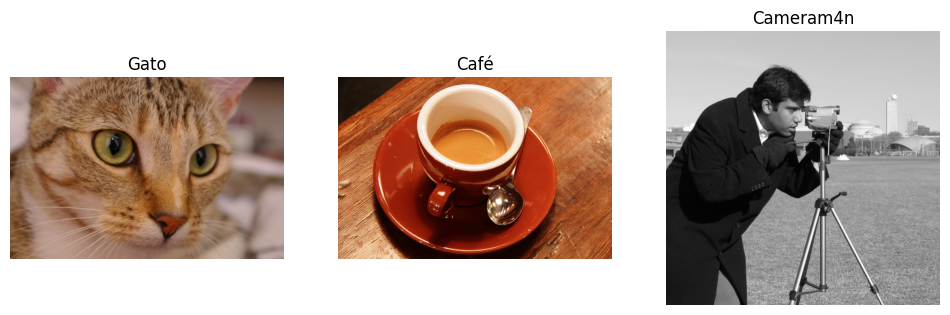

In [3]:
gato = data.cat()
cafe = data.coffee()
camera = data.camera()

mostrar([gato, cafe,camera], ['Gato', 'Café', 'Cameram4n'])

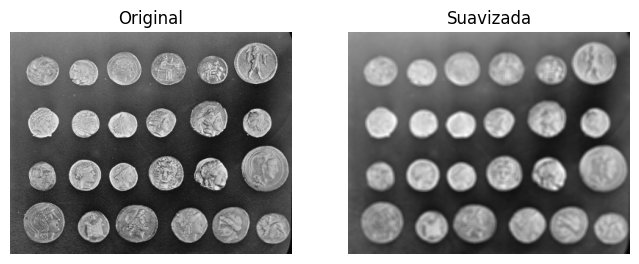

In [4]:
moedas = data.coins()
moedas_suave = cv2.GaussianBlur(moedas, (5,5), 90)#moedas, kernel, desvio padrao(quanto maior dp maior suavização)

mostrar([moedas, moedas_suave], ['Original', 'Suavizada'])

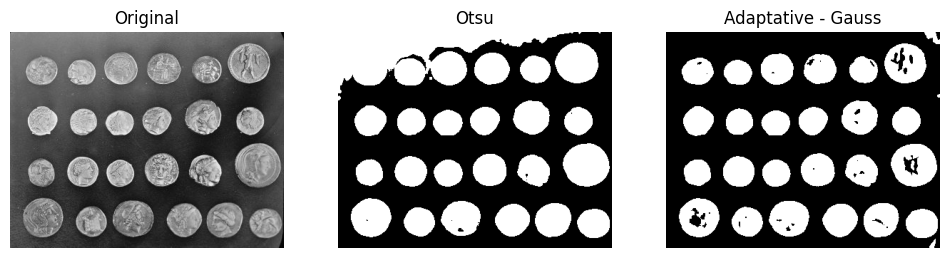

In [5]:
_, moedas_otsu = cv2.threshold(moedas_suave,
                            0,
                            255, cv2.THRESH_OTSU)

moedas_adapt = cv2.adaptiveThreshold(moedas_suave,
                                    255,
                                    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                    cv2.THRESH_BINARY,
                                    101,
                                    -10)
mostrar([moedas, moedas_otsu, moedas_adapt], ['Original', 'Otsu', 'Adaptative - Gauss'])
#

In [6]:
contornos, _ = cv2.findContours(moedas_adapt, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
print('Contornos antes: ',len(contornos))

contornos = [c for c in contornos if cv2.contourArea(c) > 500]
print('Contornos Depois: ',len(contornos))

Contornos antes:  27
Contornos Depois:  24


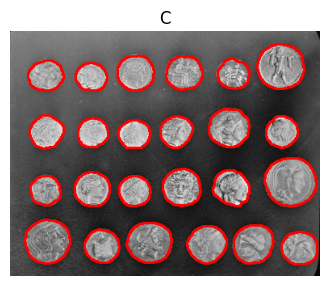

In [7]:
saida = cv2.cvtColor(moedas, cv2.COLOR_GRAY2BGR)
cv2.drawContours(saida, contornos, -1, (255,0,0), 2)
mostrar([saida],'Contornos')

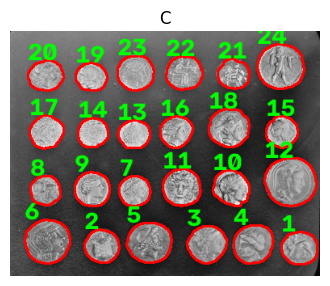

In [8]:
saida = cv2.cvtColor(moedas, cv2.COLOR_GRAY2BGR)
cv2.drawContours(saida, contornos, -1, (255,0,0), 2)

for i, c in enumerate(contornos):
 x, y, w, h = cv2.boundingRect(c)
 cv2.putText(saida, str(i+1), (x,y), cv2.FONT_HERSHEY_SIMPLEX, 1, (0,255,0), 2)

mostrar([saida],'Contornos')

## Segmentação semântica e por instância

Partindo do pipeline anterior (suavização, limiarização adaptativa e contornos), vamos gerar dois mapas de segmentação:

* **Semântica:** todos os pixels de objeto recebem a mesma classe (máscara binária).
* **Instância:** cada objeto recebe um rótulo próprio, ou seja, uma cor por objeto.

In [9]:
def segmentar(img, bloco, C, area_min, inverter=False, sigma=90):
    """Retorna os contornos dos objetos encontrados na imagem em tons de cinza."""
    suave = cv2.GaussianBlur(img, (5,5), sigma)
    tipo = cv2.THRESH_BINARY_INV if inverter else cv2.THRESH_BINARY
    binaria = cv2.adaptiveThreshold(suave, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                    tipo, bloco, C)
    contornos, _ = cv2.findContours(binaria, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    return [c for c in contornos if cv2.contourArea(c) > area_min]


def mapa_semantico(img, contornos):
    """Uma unica classe: pixel de objeto = 255, fundo = 0."""
    mascara = np.zeros(img.shape[:2], dtype=np.uint8)
    cv2.drawContours(mascara, contornos, -1, 255, thickness=-1)  # -1 preenche o contorno
    return mascara


def mapa_instancia(img, contornos):
    """Cada contorno recebe um id (1..N); fundo = 0."""
    rotulos = np.zeros(img.shape[:2], dtype=np.int32)
    for i, c in enumerate(contornos):
        cv2.drawContours(rotulos, [c], -1, i+1, thickness=-1)
    return rotulos


def colorir_instancias(rotulos):
    """Converte os rotulos em imagem RGB (fundo preto, uma cor por instancia)."""
    n = rotulos.max()
    rng = np.random.default_rng(0)
    cores = np.vstack([[0,0,0], rng.integers(40, 256, size=(n,3))]).astype(np.uint8)
    return cores[rotulos]


def comparar(img, contornos, nome_objeto):
    sem = mapa_semantico(img, contornos)
    inst = mapa_instancia(img, contornos)
    plt.figure(figsize=(15,4))
    plt.subplot(1,3,1); plt.imshow(img, cmap='gray');                plt.title('Entrada');                          plt.axis('off')
    plt.subplot(1,3,2); plt.imshow(sem, cmap='gray');                plt.title(f'Semântica (1 classe: {nome_objeto})'); plt.axis('off')
    plt.subplot(1,3,3); plt.imshow(colorir_instancias(inst));        plt.title(f'Instância (1 cor por {nome_objeto})');  plt.axis('off')
    plt.show()
    print(f'Objetos (instâncias) detectados: {len(contornos)}')
    return sem, inst

### Imagem 1: moedas (`data.coins`)

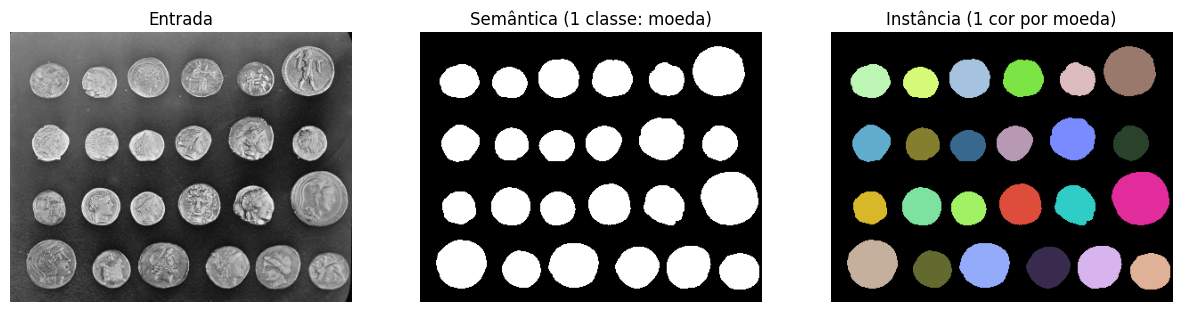

Objetos (instâncias) detectados: 24


In [10]:
moedas = data.coins()
cont_moedas = segmentar(moedas, bloco=101, C=-10, area_min=500)
sem_moedas, inst_moedas = comparar(moedas, cont_moedas, 'moeda')

### Imagem 2: texto de uma página (`data.page`)

Texto escuro sobre fundo claro, então usamos `THRESH_BINARY_INV` para que o texto vire objeto (branco), com desfoque leve (`sigma=0.8`) para não fundir o texto. Os caracteres de uma mesma palavra se tocam após a limiarização, então cada instância tende a ser uma palavra (ou trecho de palavra), e não uma letra.

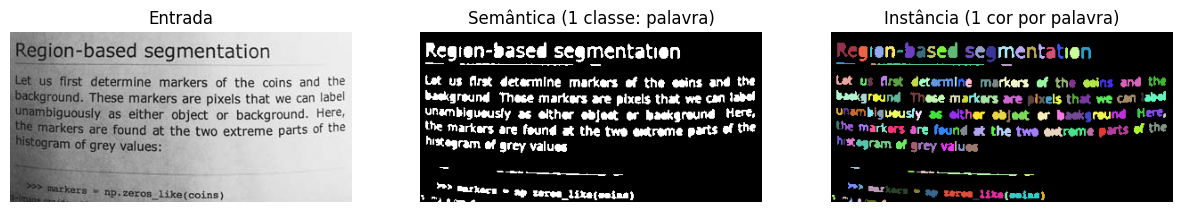

Objetos (instâncias) detectados: 154


In [11]:
pagina = data.page()
cont_pagina = segmentar(pagina, bloco=31, C=10, area_min=4, inverter=True, sigma=0.8)
sem_pagina, inst_pagina = comparar(pagina, cont_pagina, 'palavra')

In [12]:
# Comparativo numerico entre as duas imagens
for nome, sem, inst in [('Moedas', sem_moedas, inst_moedas), ('Página', sem_pagina, inst_pagina)]:
    areas = np.bincount(inst.ravel())[1:]
    print(f"{nome:7s} | instâncias: {inst.max():3d} | área média: {areas.mean():7.1f} px | "
          f"menor: {areas.min():5d} | maior: {areas.max():6d} | cobertura: {100*(sem>0).mean():.1f}% da imagem")

Moedas  | instâncias:  24 | área média:  1610.0 px | menor:  1094 | maior:   3054 | cobertura: 33.2% da imagem
Página  | instâncias: 154 | área média:    82.1 px | menor:    10 | maior:    207 | cobertura: 17.2% da imagem


## Análise: houve diferença entre as duas imagens?

Sim. Nas moedas, os objetos são grandes, bem separados e de tamanho parecido, então a segmentação semântica e a por instância concordam: 24 moedas, 24 cores. No texto, a segmentação semântica continua correta (tudo que é tinta vira uma classe só), mas a por instância fica ambígua: letras coladas viram uma única instância, e o ruído de iluminação e as linhas viram instâncias extras. A semântica não precisa separar objetos encostados, a instância precisa. Para separar letras ou moedas que se tocam seria preciso um método extra, como transformada de distância com watershed.